# Results of the FT-Transformer teammate's 12 runs

Tables and graphs of the FT-Transformer (column sets A and B) and GraphSAGE (real and shuffled links) runs, seeds 42, 1 and 2. Everything is recomputed from the saved validation and test predictions in `results/graph_vs_V/`. Runs that are not finished yet are left out, so this notebook can be opened while training is still going. Fusion with other models is Reset's part of the team plan and is not shown here.

## Setup

Loads the saved results. Nothing is trained here, and no GPU is needed. In Colab it first connects Google Drive; on the PC it finds the project folder by itself.

In [ ]:
import os
import sys
from pathlib import Path

if "google.colab" in sys.modules:   # in Colab: work in the project folder in Google Drive
    from google.colab import drive
    drive.mount("/content/drive")
    os.chdir("/content/drive/MyDrive/IEEE Fraud Detection")
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "runs.py").exists())
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))
sys.dont_write_bytecode = True   # no __pycache__ folder in the project

import pandas as pd
import report

pd.set_option("display.max_colwidth", None)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
WHAT = report.MODELS   # run name prefix -> plain words, used in every table and figure
pd.Series(WHAT, name="model")

,model
ft_A,"FT-Transformer, set A (with V)"
ft_B,"FT-Transformer, set B (no V)"
sage,"GraphSAGE, real links"
sage_shuf,"GraphSAGE, shuffled links"


## A. Finished runs

One row per finished run. Every score is recomputed from the saved predictions; **Matches** shows ✓ when it equals `runs.csv`, so nothing was typed in by hand. The chosen epoch is the one with the best validation ROC-AUC (team rule); the test set was scored once, with that epoch.

In [ ]:
report.run_table()

,Model,Seed,Chosen epoch,Minutes,val ROC-AUC,val PR-AUC,test ROC-AUC,test PR-AUC,Matches
0,"FT-Transformer, set A (with V)",42,1,34.1,0.854,0.419,0.856,0.416,✓
1,"FT-Transformer, set A (with V)",1,1,34.1,0.848,0.409,0.854,0.396,✓
2,"FT-Transformer, set A (with V)",2,3,40.4,0.852,0.416,0.847,0.398,✓
3,"FT-Transformer, set B (no V)",42,1,3.2,0.763,0.258,0.757,0.219,✓
4,"FT-Transformer, set B (no V)",1,1,3.2,0.772,0.245,0.751,0.202,✓
5,"FT-Transformer, set B (no V)",2,1,3.2,0.765,0.264,0.763,0.222,✓
6,"GraphSAGE, real links",42,2,1.7,0.789,0.190,0.754,0.141,✓
7,"GraphSAGE, real links",1,1,1.7,0.786,0.165,0.760,0.133,✓
8,"GraphSAGE, real links",2,1,1.7,0.794,0.181,0.762,0.142,✓
9,"GraphSAGE, shuffled links",42,1,2.2,0.789,0.185,0.758,0.142,✓


## B. Test scores per model

Mean over the finished seeds, with the lowest and highest seed in brackets. *Frauds caught* is the team plan's review budget: the share of all test frauds among the 1% (or 5%) highest-scored payments.

In [ ]:
report.summary_table()

,Model,Seeds,Test ROC-AUC,Test PR-AUC,"Frauds caught, top 1%","Frauds caught, top 5%"
0,"FT-Transformer, set A (with V)",3,0.853 (0.847-0.856),0.403 (0.396-0.416),0.226 (0.220-0.233),0.454 (0.447-0.458)
1,"FT-Transformer, set B (no V)",3,0.757 (0.751-0.763),0.214 (0.202-0.222),0.129 (0.123-0.136),0.352 (0.335-0.361)
2,"GraphSAGE, real links",3,0.759 (0.754-0.762),0.139 (0.133-0.142),0.092 (0.085-0.097),0.245 (0.243-0.247)
3,"GraphSAGE, shuffled links",3,0.754 (0.747-0.759),0.138 (0.131-0.142),0.093 (0.086-0.098),0.242 (0.234-0.246)


Each dot is one seed and the bar is the mean. The dashed lines are the reference paper's models (Ahmad et al. 2026, team plan p. 1).

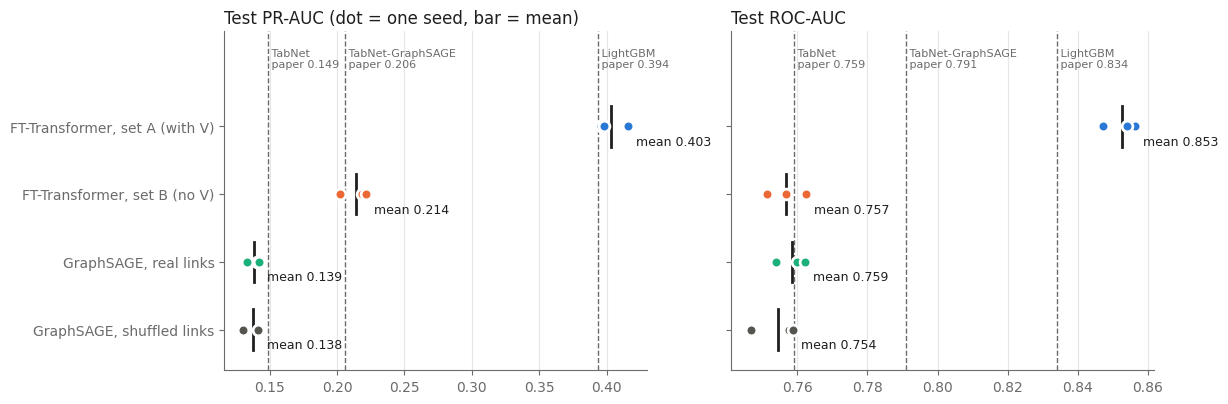

In [ ]:
report.fig_test_scores()

## C. Training curves

Validation ROC-AUC (top) and PR-AUC (bottom) after every epoch. The ring marks the epoch each run kept.

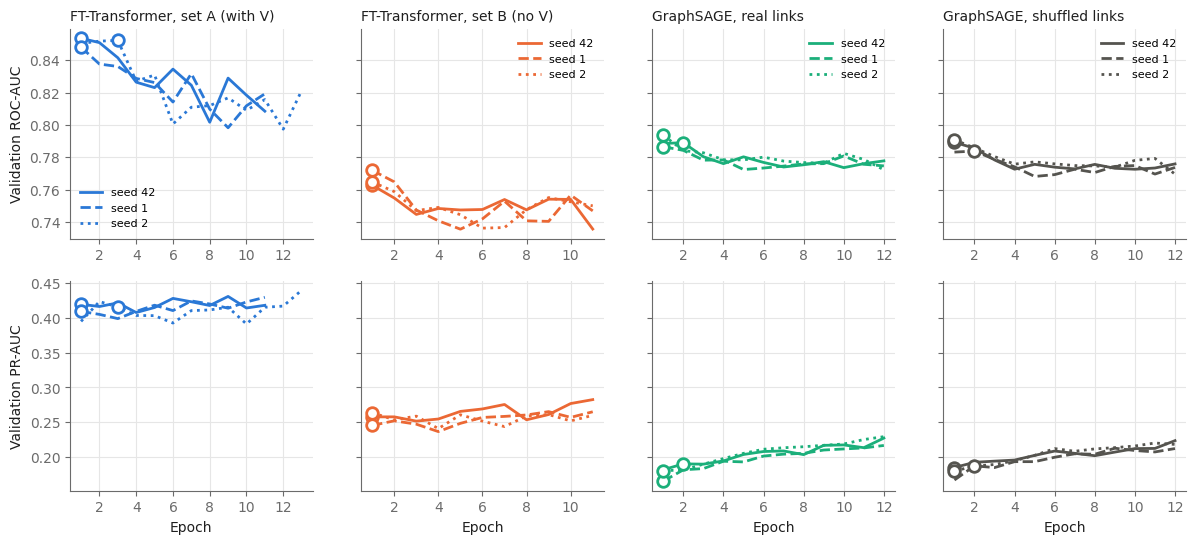

In [ ]:
report.fig_training()

## D. Overfitting

Training (dashed) vs validation (solid) ROC-AUC. When training keeps rising and validation does not, the model is memorising the training payments; the kept epoch (ring) is chosen before that gap grows.

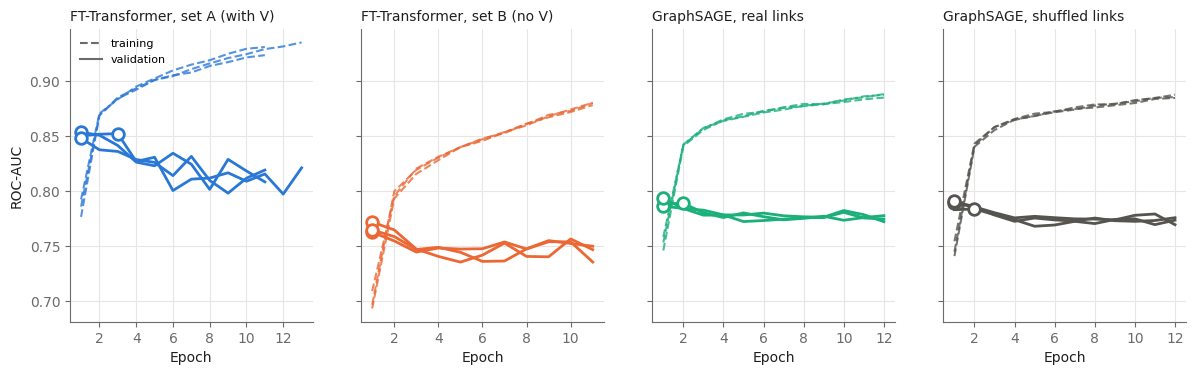

In [ ]:
report.fig_overfitting()

## E. ROC and precision-recall curves on the test set

One colour per model, one line per seed. The dashed lines are what random scores would give.

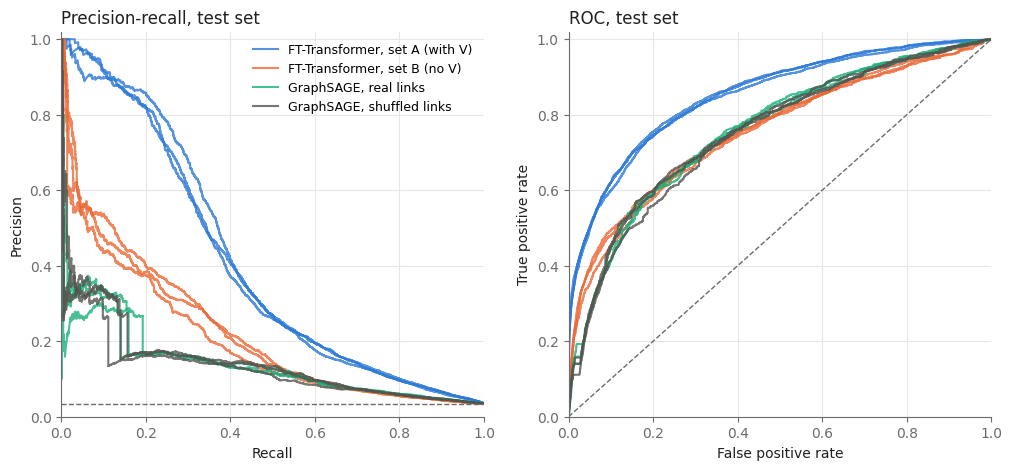

In [ ]:
report.fig_curves()

## F. Review budget

Share of all test frauds found if a team reviews the top 1% or 5% of test payments by score (team plan p. 11).

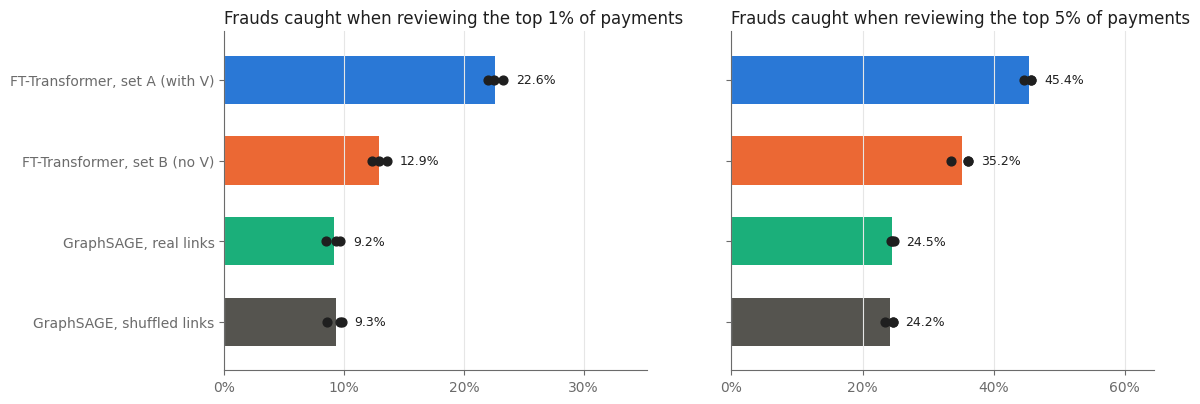

In [ ]:
report.fig_review_budget()

## G. Comparisons

Two questions with this folder's runs alone: what V1-V339 add to the FT-Transformer (set A minus set B), and whether GraphSAGE's links are real information (real minus shuffled links). Test PR-AUC differences per seed, their mean, and a 95% interval from 2,000 paired resamples of test payments. The team plan counts a difference only if the interval is above 0 and it is larger than the spread between seeds. Takes about a minute.

In [ ]:
comparisons = report.comparisons_table()
comparisons.drop(columns=[c for c in comparisons if c.startswith("_")]) if len(comparisons) else "no comparison finished yet"

,Comparison,Seeds,Seed 42,Seed 1,Seed 2,Mean difference,95% interval,Interval above 0,Seed spread,Larger than the spread
0,Set A minus set B: what V1-V339 add to the FT-Transformer,3,0.197,0.194,0.177,0.189,0.175 to 0.203,yes,0.020,yes
1,Real minus shuffled links: are GraphSAGE's links real information?,3,-0.001,0.003,0.001,0.001,-0.001 to 0.003,no,0.011,no


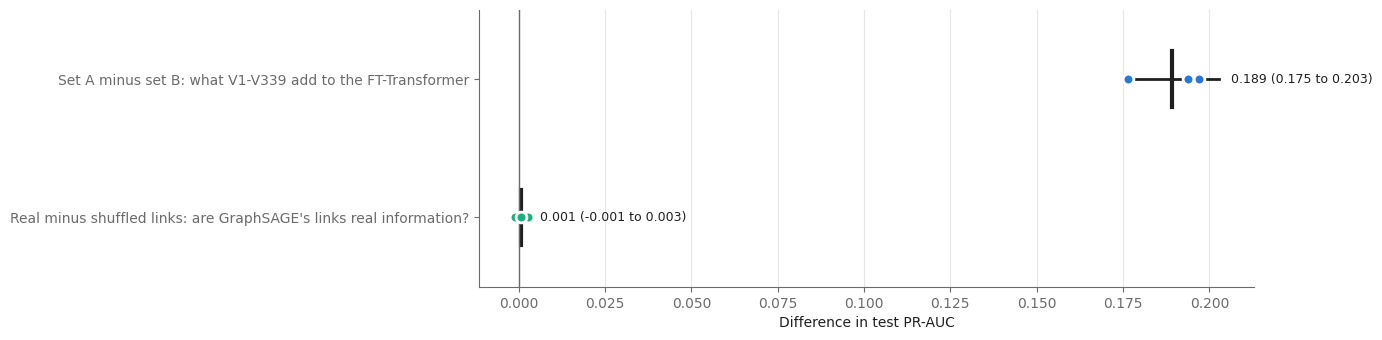

In [ ]:
report.fig_comparisons(comparisons)

Every figure is also saved to `results/figures/`.